In [1]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay


data_url = "https://huggingface.co/datasets/DElmazi/Student_Performance/resolve/main/student-mat.csv"

df = pd.read_csv(data_url, sep=";")


print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [2]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

Total missing values: 0


In [3]:


df["Pass"] = (df["G3"] >= 10).astype(int)


X = df.drop(columns=["G3", "Pass"])
y = df["Pass"]

print("Pass and Not Pass counts:")
print(y.value_counts().rename(index={0: "Not Pass", 1: "Pass"}))


Pass and Not Pass counts:
Pass
Pass        265
Not Pass    130
Name: count, dtype: int64


In [5]:


categorical_features = X.select_dtypes(include=["object"]).columns.tolist()
numeric_features = X.select_dtypes(exclude=["object"]).columns.tolist()


preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Data preparation complete!")


Training records: 316
Testing records: 79
Data preparation complete!


In [6]:


decision_tree = Pipeline([
    ("preprocessing", preprocessor),
    ("model", DecisionTreeClassifier(max_depth=5, random_state=42))
])


decision_tree.fit(X_train, y_train)


dt_predictions = decision_tree.predict(X_test)


dt_accuracy = accuracy_score(y_test, dt_predictions)

print("Decision Tree Accuracy:", round(dt_accuracy * 100, 2), "%")


Decision Tree Accuracy: 88.61 %


In [7]:


knn_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", KNeighborsClassifier(n_neighbors=5))
])


knn_model.fit(X_train, y_train)


knn_predictions = knn_model.predict(X_test)


knn_accuracy = accuracy_score(y_test, knn_predictions)

print("KNN Accuracy:", round(knn_accuracy * 100, 2), "%")


KNN Accuracy: 77.22 %


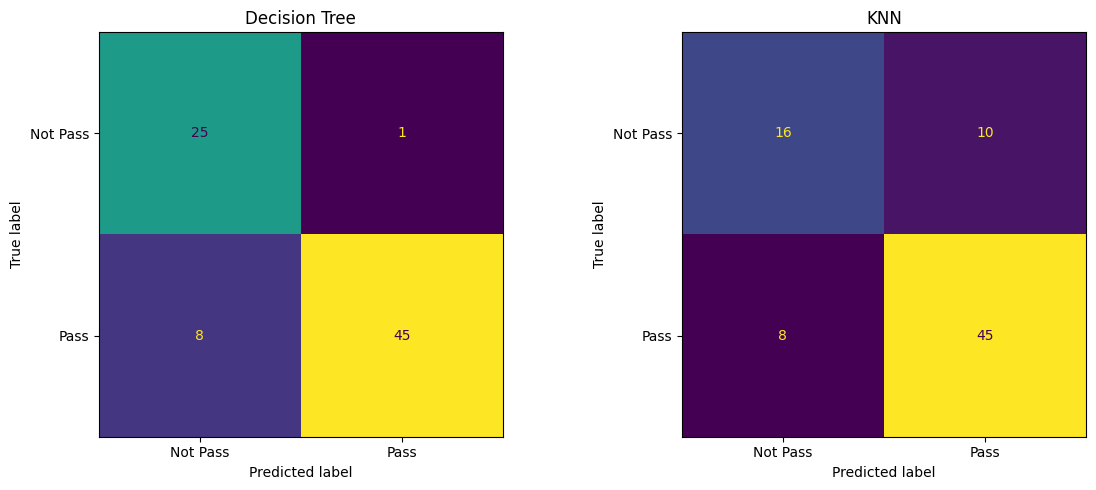

In [8]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))


dt_cm = confusion_matrix(y_test, dt_predictions, labels=[0, 1])
ConfusionMatrixDisplay(
    confusion_matrix=dt_cm,
    display_labels=["Not Pass", "Pass"]
).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Decision Tree")


knn_cm = confusion_matrix(y_test, knn_predictions, labels=[0, 1])
ConfusionMatrixDisplay(
    confusion_matrix=knn_cm,
    display_labels=["Not Pass", "Pass"]
).plot(ax=axes[1], colorbar=False)
axes[1].set_title("KNN")

plt.tight_layout()
plt.show()


In [9]:


comparison = pd.DataFrame({
    "Model": ["Decision Tree", "K-Nearest Neighbors (KNN)"],
    "Accuracy (%)": [
        round(dt_accuracy * 100, 2),
        round(knn_accuracy * 100, 2)
    ]
})

display(comparison)


if dt_accuracy > knn_accuracy:
    print("Better-performing model: Decision Tree")
elif knn_accuracy > dt_accuracy:
    print("Better-performing model: KNN")
else:
    print("Both models have equal accuracy.")


,Model,Accuracy (%)
0,Decision Tree,88.61
1,K-Nearest Neighbors (KNN),77.22


Better-performing model: Decision Tree




In this project, two machine learning algorithms, Decision Tree and K-Nearest Neighbors (KNN), were implemented to predict student pass or not-pass outcomes. The Decision Tree model achieved an accuracy of 88.61%, while KNN achieved 77.22%. Therefore, the Decision Tree performed better on the test dataset. Confusion matrices were also used to compare the correct and incorrect predictions made by both models. Through this project, I learned how to load and prepare a dataset, train machine learning models, evaluate their performance, and compare their accuracy.